# Exploratory Data Analysis — Global Weather Repository

This notebook explores the **raw** Kaggle dataset ([Global Weather Repository](https://www.kaggle.com/datasets/nelgiriyewithana/global-weather-repository)) step by step, before any cleaning.
It is the reasoning behind the decisions taken in the production pipeline (`src/weather/`, run with `uv run dvc repro`):
- which rows to drop;
- which values are invalid;
- how outliers are treated;
- why the snapshot hour matters;
- why one whole day had to be discarded.

> *PM Accelerator mission (PMA Kids):* "Our mission is to break down financial barriers and achieve educational fairness. With the goal of establishing 200 schools worldwide over the next 20 years, we aim to empower more kids for a better future in their life and career, simultaneously fostering a diverse landscape in the tech industry." — [pmaccelerator.io](https://www.pmaccelerator.io/)

**Contents**
1. Setup and first look
2. Data types, missing values, duplicates
3. Physically impossible values and sentinels
4. Locations, coverage and country names
5. The time axis and the snapshot-hour drift
6. Temperature
7. Precipitation
8. Other weather variables
9. Correlations
10. Air quality
11. Batch-level data corruption
12. Spatial overview
13. Summary: what the pipeline does about it

The data comes from `uv run dvc pull` (or `uv run dvc repro download`). Every path is read from `.env` through `weather.utils.config.get_settings()`.

## 1. Setup and first look

In [1]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from weather.data.clean import canonical_country, country_to_continent
from weather.enums import CleaningColumns, CleaningRules
from weather.utils.config import get_settings
from weather.utils.plotting import (
    CONTINENT_COLORS, CONTINENT_ORDER, CRITICAL, DIV_CMAP, INK_2, MUTED, SEQ_CMAP, SERIES, apply_style,
)

# weather.utils.plotting selects the non-interactive Agg backend for the pipeline -> switch back to inline
%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
apply_style()
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50, "display.width", 160)

S = get_settings()
raw = pd.read_csv(S.raw_csv)
print(f"{S.raw_csv.name}: {raw.shape[0]:,} rows x {raw.shape[1]} columns, "
      f"{raw.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
raw.head()

GlobalWeatherRepository.csv: 170,928 rows x 41 columns, 74 MB in memory


,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,wind_mph,wind_kph,wind_degree,wind_direction,pressure_mb,pressure_in,precip_mm,precip_in,humidity,cloud,feels_like_celsius,feels_like_fahrenheit,visibility_km,visibility_miles,uv_index,gust_mph,gust_kph,air_quality_Carbon_Monoxide,air_quality_Ozone,air_quality_Nitrogen_dioxide,air_quality_Sulphur_dioxide,air_quality_PM2.5,air_quality_PM10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
0,Afghanistan,Kabul,34.52,69.18,Asia/Kabul,1715849100,2024-05-16 13:15,26.6,79.8,Partly Cloudy,8.3,13.3,338,NNW,1012.0,29.89,0.0,0.00,24,30,25.3,77.5,10.0,6.0,7.0,9.5,15.3,277.0,103.0,1.1,0.2,8.4,26.6,1,1,04:50 AM,06:50 PM,12:12 PM,01:11 AM,Waxing Gibbous,55
1,Albania,Tirana,41.33,19.82,Europe/Tirane,1715849100,2024-05-16 10:45,19.0,66.2,Partly cloudy,6.9,11.2,320,NW,1012.0,29.88,0.1,0.00,94,75,19.0,66.2,10.0,6.0,5.0,11.4,18.4,193.6,97.3,0.9,0.1,1.1,2.0,1,1,05:21 AM,07:54 PM,12:58 PM,02:14 AM,Waxing Gibbous,55
2,Algeria,Algiers,36.76,3.05,Africa/Algiers,1715849100,2024-05-16 09:45,23.0,73.4,Sunny,9.4,15.1,280,W,1011.0,29.85,0.0,0.00,29,0,24.6,76.4,10.0,6.0,5.0,13.9,22.3,540.7,12.2,65.1,13.4,10.4,18.4,1,1,05:40 AM,07:50 PM,01:15 PM,02:14 AM,Waxing Gibbous,55
3,Andorra,Andorra La Vella,42.50,1.52,Europe/Andorra,1715849100,2024-05-16 10:45,6.3,43.3,Light drizzle,7.4,11.9,215,SW,1007.0,29.75,0.3,0.01,61,100,3.8,38.9,2.0,1.0,2.0,8.5,13.7,170.2,64.4,1.6,0.2,0.7,0.9,1,1,06:31 AM,09:11 PM,02:12 PM,03:31 AM,Waxing Gibbous,55
4,Angola,Luanda,-8.84,13.23,Africa/Luanda,1715849100,2024-05-16 09:45,26.0,78.8,Partly cloudy,8.1,13.0,150,SSE,1011.0,29.85,0.0,0.00,89,50,28.7,83.6,10.0,6.0,8.0,12.5,20.2,2964.0,19.0,72.7,31.5,183.4,262.3,5,10,06:12 AM,05:55 PM,01:17 PM,12:38 AM,Waxing Gibbous,55


## 2. Data types, missing values and duplicates

In [2]:
info = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
})
info

,dtype,non_null,n_unique,example
country,str,170928,211,Afghanistan
location_name,str,170928,268,Kabul
latitude,float64,170928,422,34.52
longitude,float64,170928,428,69.18
timezone,str,170928,201,Asia/Kabul
last_updated_epoch,int64,170928,1575,1715849100
last_updated,str,170928,28420,2024-05-16 13:15
temperature_celsius,float64,170928,709,26.6
temperature_fahrenheit,float64,170928,1180,79.8
condition_text,str,170928,58,Partly Cloudy


In [3]:
print("Missing cells       :", int(raw.isna().sum().sum()))
print("Exact duplicate rows:", int(raw.duplicated().sum()))
raw["last_updated"] = pd.to_datetime(raw["last_updated"])
raw["date"] = raw["last_updated"].dt.normalize()
same_day = raw.duplicated(["location_name", "date"]).sum()
print("Same location + same day (more than one snapshot):", int(same_day))
print("Date range:", raw["date"].min().date(), "->", raw["date"].max().date(),
      f"({raw['date'].nunique()} distinct days)")

Missing cells       : 0
Exact duplicate rows: 0
Same location + same day (more than one snapshot): 417
Date range: 2024-05-16 -> 2026-10-13 (880 distinct days)


**Observations.**
- There are no empty cells and no exact duplicates. Missing values are hidden as **sentinels** instead (see §3).
- Some locations have two snapshots on the same day; the pipeline keeps the latest.
- Seven columns are imperial copies of metric ones (°F, mph, inches, miles), so they carry no extra information:

In [4]:
pairs = [("temperature_celsius", "temperature_fahrenheit"), ("wind_kph", "wind_mph"),
         ("precip_mm", "precip_in"), ("pressure_mb", "pressure_in")]
pd.Series({f"{a} ~ {b}": raw[a].corr(raw[b]) for a, b in pairs}, name="Pearson r").round(4).to_frame()

,Pearson r
temperature_celsius ~ temperature_fahrenheit,1.0000
wind_kph ~ wind_mph,1.0000
precip_mm ~ precip_in,0.9983
pressure_mb ~ pressure_in,0.9998


## 3. Physically impossible values and sentinels

In [5]:
df = raw.drop(columns=CleaningColumns.IMPERIAL_DUPLICATES).rename(columns=CleaningColumns.AIR_QUALITY_RENAMES)
rows = []
for col, (lo, hi) in CleaningRules.VALID_RANGES.items():
    s = df[col]
    rows.append({"variable": col, "min": s.min(), "max": s.max(), "valid range": f"[{lo}, {hi}]",
                 "below": int((s < lo).sum()), "above": int((s > hi).sum())})
pd.DataFrame(rows).set_index("variable")

,min,max,valid range,below,above
variable,,,,,
temperature_celsius,-29.80,79.300,"[-60, 57]",0,1
feels_like_celsius,-40.00,81.300,"[-75, 70]",0,1
wind_kph,3.60,2963.200,"[0, 250]",0,3
gust_kph,3.60,2970.400,"[0, 350]",0,1
pressure_mb,771.00,3006.000,"[870, 1085]",12,2
precip_mm,0.00,74.520,"[0, 400]",0,0
humidity,2.00,100.000,"[0, 100]",0,0
cloud,0.00,100.000,"[0, 100]",0,0
visibility_km,0.00,32.000,"[0, 50]",0,0


- **Sentinels**: `-9999` in CO and SO₂ means "not measured".
- **Instrument or API glitches**: pressure of 3006 mb, wind of 2963 kph, a temperature of 79 °C.
- The pipeline sets these to NaN and imputes them within each city.

## 4. Locations, coverage and country names

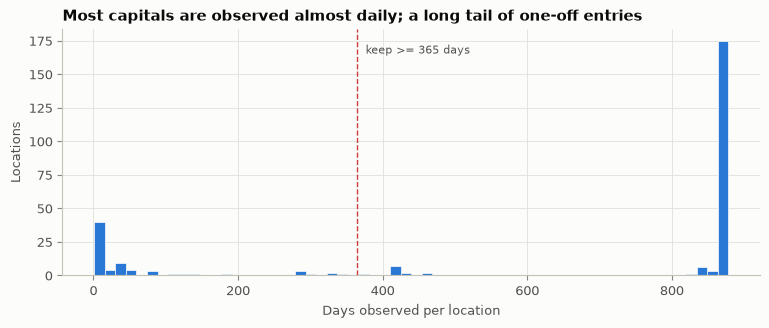

268 location strings, 71 below the threshold (3790 rows)


,days observed
location_name,
-Kingdom,1
City Of San Marino,1
Saint Petersburg,1
Beijing Shi,1
New Guatemala,1
Mexico (Grupo Mexico),1
Ivory Ivory Ban,1
Moldova,1
Kiyabo,1


In [6]:
obs = raw.groupby("location_name")["date"].nunique().sort_values()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(obs, bins=60, color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(S.clean.min_obs_per_location, color=CRITICAL, linestyle="--", linewidth=1)
ax.annotate(f"keep >= {S.clean.min_obs_per_location} days", (S.clean.min_obs_per_location, ax.get_ylim()[1] * 0.9),
            xytext=(6, 0), textcoords="offset points", color=INK_2, fontsize=8)
ax.set_xlabel("Days observed per location"); ax.set_ylabel("Locations")
ax.set_title("Most capitals are observed almost daily; a long tail of one-off entries")
plt.show()
print(f"{len(obs)} location strings, {(obs < S.clean.min_obs_per_location).sum()} below the threshold "
      f"({raw[raw.location_name.isin(obs[obs < S.clean.min_obs_per_location].index)].shape[0]} rows)")
obs.head(10).to_frame("days observed")

In [7]:
# the same capital is sometimes reported under a translated country name
multi = raw.groupby("location_name")["country"].unique()
multi = multi[multi.str.len() > 1]
print(f"{len(multi)} locations carry more than one country label, e.g.:")
multi.head(8).to_frame("country labels")

15 locations carry more than one country label, e.g.:


,country labels
location_name,
Beirut,"[Lebanon, Польша]"
Bern,"[Switzerland, Bélgica]"
Bogot,"[Bulgaria, Hungary]"
Grenada,"[USA United States of America, United States o..."
Kingstown,"[Saint Vincent and the Grenadines, Saint-Vince..."
Lom,"[Bulgaria, Russia, Norway]"
Mbabane,"[Swaziland, Senegal]"
Moroni,"[Comoros, USA United States of America, Komore..."


In [8]:
kept = raw[raw["location_name"].isin(obs[obs >= S.clean.min_obs_per_location].index)].copy()
kept["country"] = canonical_country(kept)
kept["continent"] = kept["country"].map({c: country_to_continent(c) for c in kept["country"].unique()})
summary = kept.groupby("continent")["location_name"].nunique().reindex(CONTINENT_ORDER)
print("Unmapped countries:", sorted(kept.loc[kept.continent == "Unknown", "country"].unique()) or "none")
summary.to_frame("capitals")

Unmapped countries: none


,capitals
continent,
Africa,52
Asia,51
Europe,46
North America,23
South America,12
Oceania,13


## 5. The time axis and the snapshot-hour drift

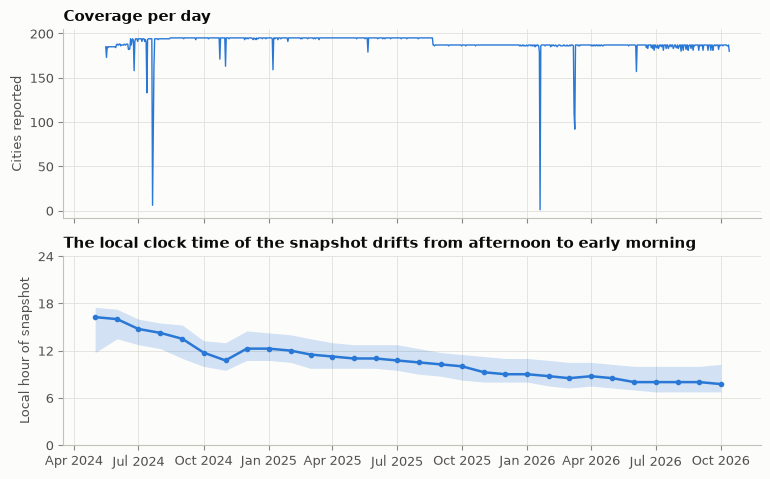

In [9]:
kept["local_hour"] = kept["last_updated"].dt.hour + kept["last_updated"].dt.minute / 60
per_day = kept.groupby("date")["location_name"].nunique()
h = kept.assign(month=kept["date"].dt.to_period("M").dt.to_timestamp()).groupby("month")["local_hour"]

fig, axes = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True)
axes[0].plot(per_day.index, per_day, color=SERIES[0], linewidth=1)
axes[0].set_ylabel("Cities reported"); axes[0].set_title("Coverage per day")
axes[1].fill_between(h.quantile(.25).index, h.quantile(.25), h.quantile(.75), color=SERIES[0], alpha=.2, linewidth=0)
axes[1].plot(h.median().index, h.median(), color=SERIES[0], marker="o", markersize=3)
axes[1].set_ylabel("Local hour of snapshot"); axes[1].set_ylim(0, 24); axes[1].set_yticks([0, 6, 12, 18, 24])
axes[1].set_title("The local clock time of the snapshot drifts from afternoon to early morning")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

This is the most important finding of the EDA. The dataset holds **one instantaneous snapshot per day**, not a daily mean, and its local time drifts from about 16:30 to about 07:45 over the record.

Temperature follows a strong daily cycle, so later records are taken closer to the daily minimum. Any naive trend will therefore show cooling that comes from the sampling schedule, not the climate. The pipeline keeps `local_hour` as a covariate: it is used in the trend models and is a forecasting feature (`hour_sin`, `hour_cos`).

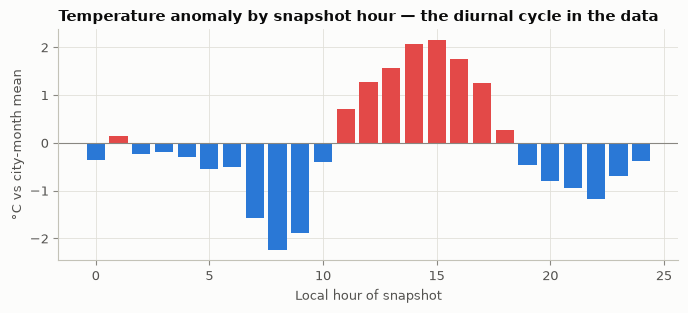

In [10]:
# how strongly does temperature depend on the snapshot hour? (deviation from each city's monthly mean)
kept["month"] = kept["date"].dt.month
dev = kept["temperature_celsius"] - kept.groupby(["location_name", "month"])["temperature_celsius"].transform("mean")
by_hour = dev.groupby(kept["local_hour"].round()).agg(["mean", "count"])
by_hour = by_hour[by_hour["count"] > 500]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(by_hour.index, by_hour["mean"], color=[SERIES[7] if v > 0 else SERIES[0] for v in by_hour["mean"]], width=0.8)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("Local hour of snapshot"); ax.set_ylabel("°C vs city-month mean")
ax.set_title("Temperature anomaly by snapshot hour — the diurnal cycle in the data")
plt.show()

## 6. Temperature

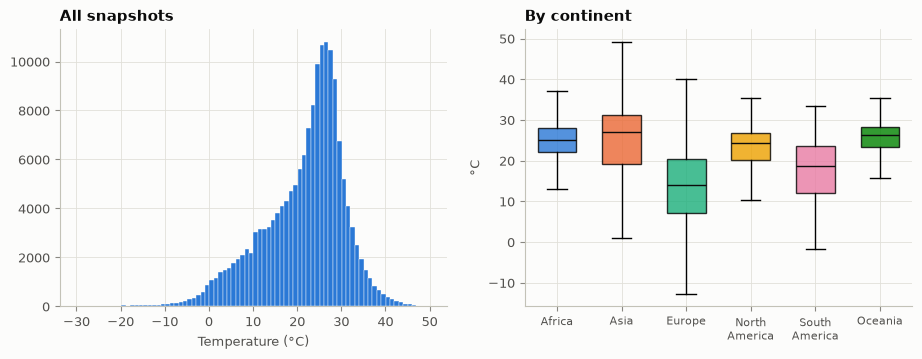

,count,mean,std,min,25%,50%,75%,max
temperature_celsius,167138.0,21.46,9.26,-29.8,16.2,23.6,27.7,79.3


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(kept["temperature_celsius"].clip(-40, 50), bins=80, color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.3)
axes[0].set_xlabel("Temperature (°C)"); axes[0].set_title("All snapshots")
data = [kept.loc[kept.continent == c, "temperature_celsius"].clip(-40, 50) for c in CONTINENT_ORDER]
bp = axes[1].boxplot(data, patch_artist=True, showfliers=False, widths=0.6, medianprops={"color": "#0b0b0b"})
for patch, c in zip(bp["boxes"], CONTINENT_ORDER, strict=True):
    patch.set_facecolor(CONTINENT_COLORS[c]); patch.set_alpha(0.8)
axes[1].set_xticks(range(1, 7), [c.replace(" ", "\n") for c in CONTINENT_ORDER], fontsize=8)
axes[1].set_ylabel("°C"); axes[1].set_title("By continent")
plt.show()
kept["temperature_celsius"].describe().round(2).to_frame().T

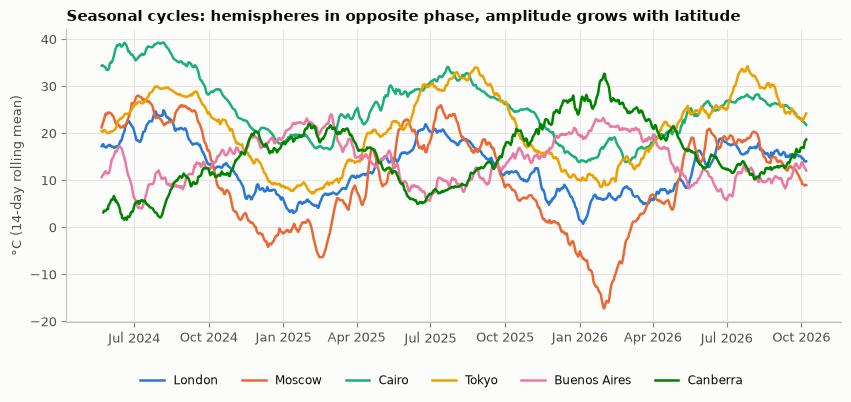

In [12]:
cities = ["London", "Moscow", "Cairo", "Tokyo", "Buenos Aires", "Canberra"]
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, c in enumerate(cities):
    g = kept[kept.location_name == c].set_index("date")["temperature_celsius"].sort_index()
    ax.plot(g.index, g.rolling(14, center=True).mean(), color=SERIES[i], label=c)
ax.set_ylabel("°C (14-day rolling mean)"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Seasonal cycles: hemispheres in opposite phase, amplitude grows with latitude")
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=6, frameon=False)
plt.show()

## 7. Precipitation

Dry snapshots: 67.4%   99th pct: 2.11 mm   max: 74.5 mm


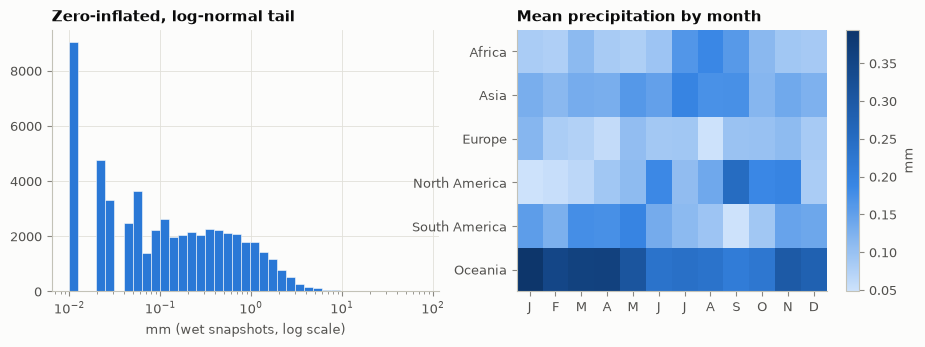

In [13]:
p = kept["precip_mm"]
print(f"Dry snapshots: {(p == 0).mean():.1%}   99th pct: {p.quantile(.99):.2f} mm   max: {p.max():.1f} mm")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
wet = p[p > 0]
axes[0].hist(wet, bins=np.logspace(np.log10(wet.min()), np.log10(wet.max()), 40), color=SERIES[0],
             edgecolor="#fcfcfb", linewidth=0.4)
axes[0].set_xscale("log"); axes[0].set_xlabel("mm (wet snapshots, log scale)"); axes[0].set_title("Zero-inflated, log-normal tail")
mon = kept.assign(m=kept.date.dt.month).groupby(["continent", "m"])["precip_mm"].mean().unstack().reindex(CONTINENT_ORDER)
im = axes[1].imshow(mon.values, aspect="auto", cmap=SEQ_CMAP)
axes[1].set_xticks(range(12), list("JFMAMJJASOND")); axes[1].set_yticks(range(6), CONTINENT_ORDER); axes[1].grid(False)
axes[1].set_title("Mean precipitation by month"); fig.colorbar(im, ax=axes[1], label="mm")
plt.show()

Precipitation has a zero-inflated, heavy-tailed distribution, so an IQR fence would flag every rainy day. The pipeline caps it at the global 99.9th percentile instead.

## 8. Other weather variables

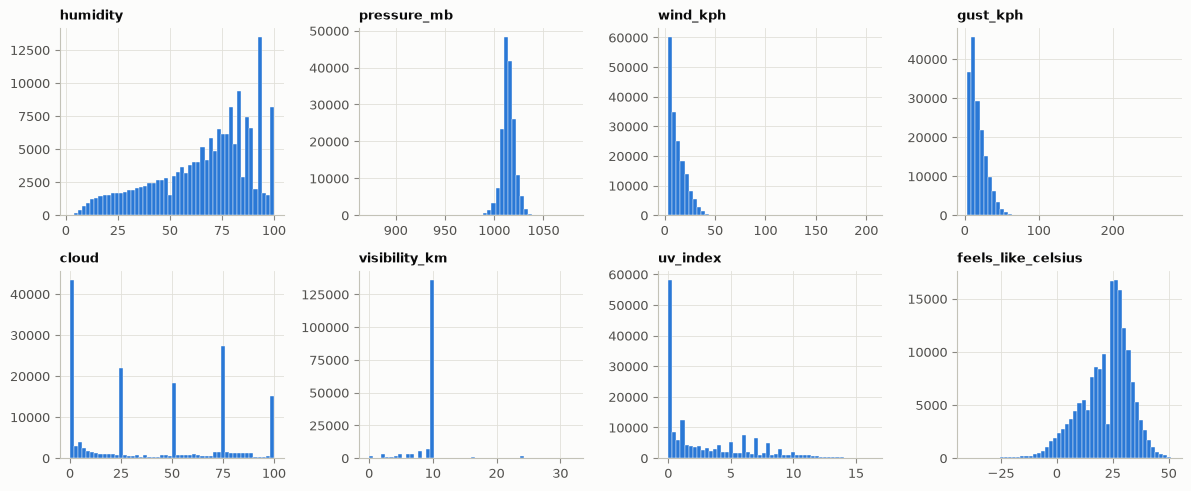

Share of visibility values exactly 10 km: 79.6%


In [14]:
cols = ["humidity", "pressure_mb", "wind_kph", "gust_kph", "cloud", "visibility_km", "uv_index", "feels_like_celsius"]
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, c in zip(axes.flat, cols, strict=True):
    lo, hi = CleaningRules.VALID_RANGES.get(c, (None, None))
    s = df[c]
    s = s[(s >= lo) & (s <= hi)] if lo is not None else s
    ax.hist(s, bins=50, color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.3)
    ax.set_title(c, fontsize=9.5)
plt.tight_layout(); plt.show()
print("Share of visibility values exactly 10 km:", f"{(df['visibility_km'] == 10).mean():.1%}")

- Visibility is reported as exactly **10 km** most of the time, so its IQR is 0. A per-city IQR fence would flag every other value, which is why the pipeline only applies a validity check to it.
- Wind and gust are right-skewed, with glitch values in the thousands of kph.

## 9. Correlations

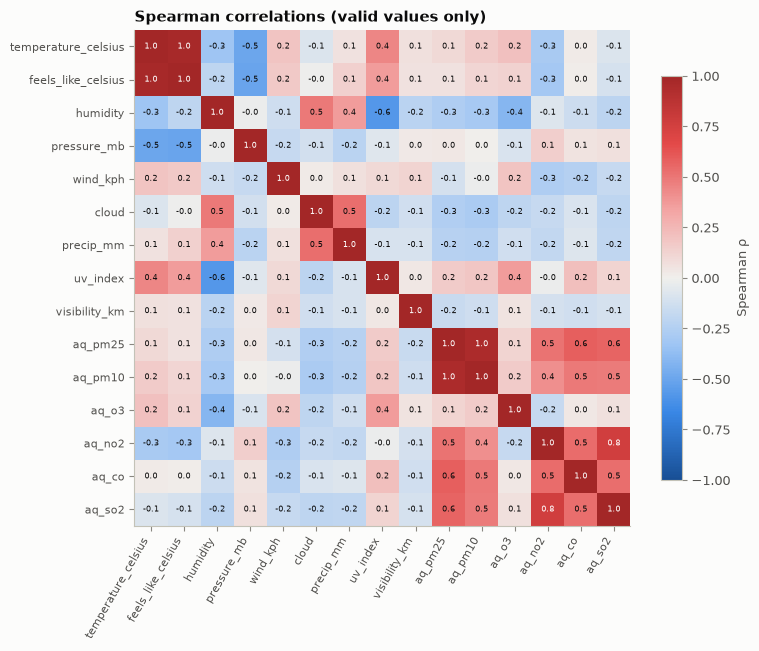

In [15]:
num = ["temperature_celsius", "feels_like_celsius", "humidity", "pressure_mb", "wind_kph", "cloud", "precip_mm",
       "uv_index", "visibility_km", "aq_pm25", "aq_pm10", "aq_o3", "aq_no2", "aq_co", "aq_so2"]
valid = df[num].copy()
for c in num:
    lo, hi = CleaningRules.VALID_RANGES.get(c, (-np.inf, np.inf))
    valid.loc[(valid[c] < lo) | (valid[c] > hi), c] = np.nan
corr = valid.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(num)), num, fontsize=8)
ax.grid(False)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6,
                color="#ffffff" if abs(corr.iloc[i, j]) > .6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=.75, label="Spearman ρ"); ax.set_title("Spearman correlations (valid values only)")
plt.show()

## 10. Air quality

          mean    50%     99%      max
aq_pm25   22.5   13.0   150.4   1614.1
aq_pm10   45.0   18.5   449.7   5899.3
aq_o3     57.8   54.0   160.0    480.7
aq_no2    13.9    5.4   108.0    427.7
aq_so2     9.6    2.3   106.7    521.3
aq_co    415.0  264.6  2854.1  38879.4


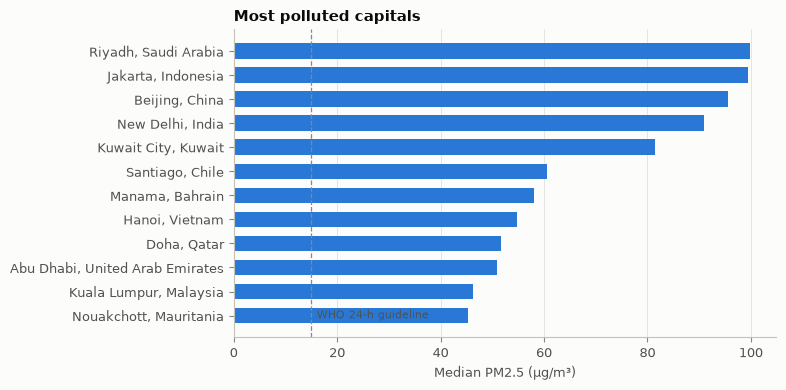

In [16]:
aq = ["aq_pm25", "aq_pm10", "aq_o3", "aq_no2", "aq_so2", "aq_co"]
aqv = valid[aq]
print(aqv.describe(percentiles=[.5, .99]).T[["mean", "50%", "99%", "max"]].round(1))
top = kept.assign(pm=valid["aq_pm25"]).groupby(["location_name", "country"])["pm"].median().nlargest(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([f"{a}, {b}" for a, b in top.index], top.values, color=SERIES[0], height=.65)
ax.axvline(15, color=MUTED, linestyle="--", linewidth=.9)
ax.annotate("WHO 24-h guideline", (15, 0), xytext=(4, -2), textcoords="offset points", fontsize=8, color=INK_2)
ax.set_xlabel("Median PM2.5 (µg/m³)"); ax.grid(axis="y", visible=False); ax.set_title("Most polluted capitals")
plt.show()

## 11. Batch-level data corruption

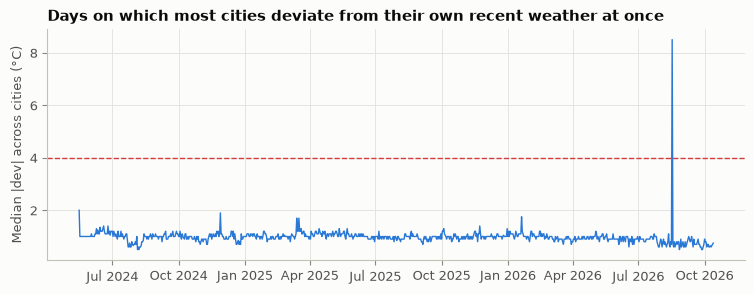

Worst day: 2026-08-17 (median deviation 8.5 °C; normal ≈ 1.0 °C)


,location_name,country,temperature_celsius,last_updated
159753,Oslo,Norway,-7.3,2026-08-17 08:00:00
159705,Dublin,Ireland,-4.0,2026-08-17 06:45:00
159792,Stockholm,Sweden,-3.5,2026-08-17 08:00:00
159670,Copenhagen,Denmark,-3.0,2026-08-17 08:00:00
159683,Helsinki,Finland,-2.3,2026-08-17 09:00:00
159679,Tallinn,Estonia,-2.1,2026-08-17 08:45:00


In [17]:
k = kept.sort_values(["location_name", "date"])
med = k.groupby("location_name")["temperature_celsius"].transform(lambda s: s.rolling(15, center=True, min_periods=5).median())
day_dev = (k["temperature_celsius"] - med).abs().groupby(k["date"]).median()
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(day_dev.index, day_dev, color=SERIES[0], linewidth=1)
ax.axhline(S.clean.corrupt_day_threshold_c, color=CRITICAL, linestyle="--", linewidth=1)
ax.set_ylabel("Median |dev| across cities (°C)"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Days on which most cities deviate from their own recent weather at once")
plt.show()
bad = day_dev.idxmax()
print("Worst day:", bad.date(), f"(median deviation {day_dev.max():.1f} °C; normal ≈ {day_dev.median():.1f} °C)")
k[k.date == bad].nsmallest(6, "temperature_celsius")[["location_name", "country", "temperature_celsius", "last_updated"]]

On 17 August 2026 the feed reports mid-winter values for summer cities. One example is Riyadh at about 15 °C in August, and dozens of capitals shift together on the same day.

A per-city outlier fence cannot catch this because every individual value is plausible somewhere. A cross-city detector catches it immediately, so the pipeline nulls that day's weather values and re-imputes them.

## 12. Spatial overview

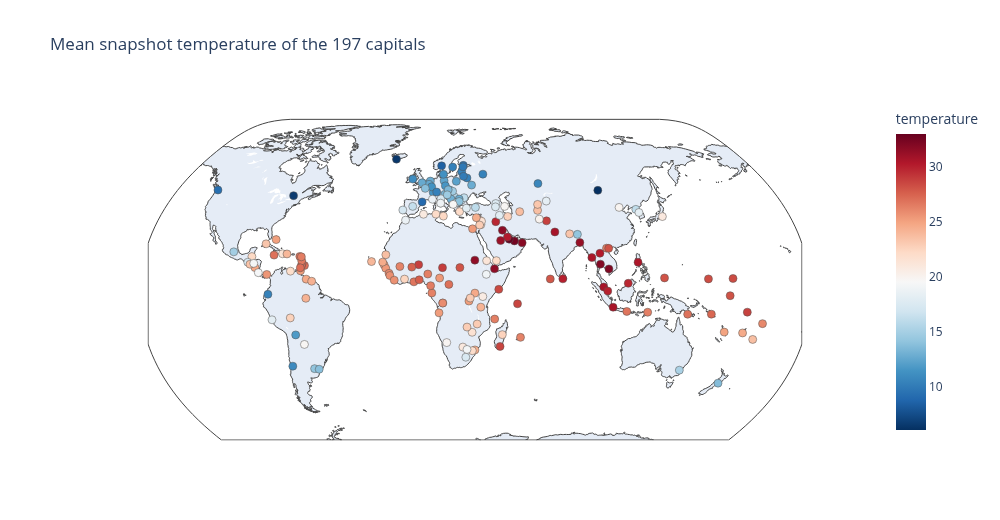

In [18]:
import plotly.express as px

loc = kept.groupby("location_name").agg(country=("country", "first"), lat=("latitude", "median"),
                                        lon=("longitude", "median"), temperature=("temperature_celsius", "mean"))
fig = px.scatter_geo(loc.reset_index(), lat="lat", lon="lon", color="temperature", hover_name="location_name",
                     color_continuous_scale="RdBu_r", projection="natural earth",
                     title="Mean snapshot temperature of the 197 capitals")
fig.update_traces(marker={"size": 8, "line": {"width": .5, "color": "#52514e"}})
try:  # static image keeps the notebook small and renders on GitHub
    display(Image(fig.to_image(format="png", width=1000, height=520)))
except Exception as exc:  # kaleido needs Chrome
    print("static export unavailable:", exc)

## 13. Summary: what the pipeline does about it

| Finding | Pipeline decision (`src/weather/data/clean.py`, `features.py`) |
|---|---|
| 7 imperial duplicate columns | dropped |
| 71 location strings with fewer than 365 days | dropped (one-off or mis-named entries) |
| translated country names | each location mapped to its most frequent country label; continent via `pycountry-convert` |
| two snapshots on the same day | keep the latest |
| sentinels (-9999) and physically impossible values | set to NaN, then imputed per city (time interpolation, then city median) |
| outliers in roughly symmetric variables | capped at a per-city 3×IQR fence and flagged |
| heavy-tailed precipitation and pollutants | capped at the global 99.9th percentile |
| visibility is almost always 10 km | validity check only |
| snapshot-hour drift (16:30 → 07:45) | `local_hour` kept as a covariate (`hour_sin`, `hour_cos`) in trend and forecasting models |
| corrupted batch on 17 Aug 2026 | the whole day's weather is nulled and re-imputed |

Continue with `uv run dvc repro` and see `reports/latex/main.pdf` for the modelling results.